# NHS Flu Vaccinations December 2025

* The data source contains information on the number, type and cost of flu vaccines administered by community pharmacies as part of the NHS seasonal influenza vaccination advanced service (running September to March each year). 
* The service exists to reduce unplanned hospital admissions and pressure on A&E. 
* The dataset is released for those interested in public spending, delivery of the healthcare service and the role of community pharmacies in the NHS. 
* It was chosen as a real-world dataset of a managable size, to practice exploratory data analysis.

## Ingestion

In [60]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/pharmacy_adult_flu_pay_current_202512.csv")

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
pd.set_option('display.expand_frame_repr', False)

- Allowing the data to span the full width of the output was very helpful for looking over the tables.

## Validation

<class 'pandas.DataFrame'>
RangeIndex: 25276 entries, 0 to 25275
Data columns (total 19 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   FLU_SEASON_START_MONTH                  25276 non-null  str    
 1   LATEST_PROCESSED_MONTH                  25276 non-null  str    
 2   REGION_CODE                             25276 non-null  str    
 3   REGION_NAME                             25276 non-null  str    
 4   ICB_CODE                                25276 non-null  str    
 5   ICB_NAME                                25276 non-null  str    
 6   DISPENSER_CODE                          25276 non-null  str    
 7   DISPENSER_NAME                          25276 non-null  str    
 8   DISPENSER_TRADING_NAME                  24619 non-null  str    
 9   MANUFACTURER                            25276 non-null  str    
 10  VACCINE_NAME                            25276 non-null  str    
 11  

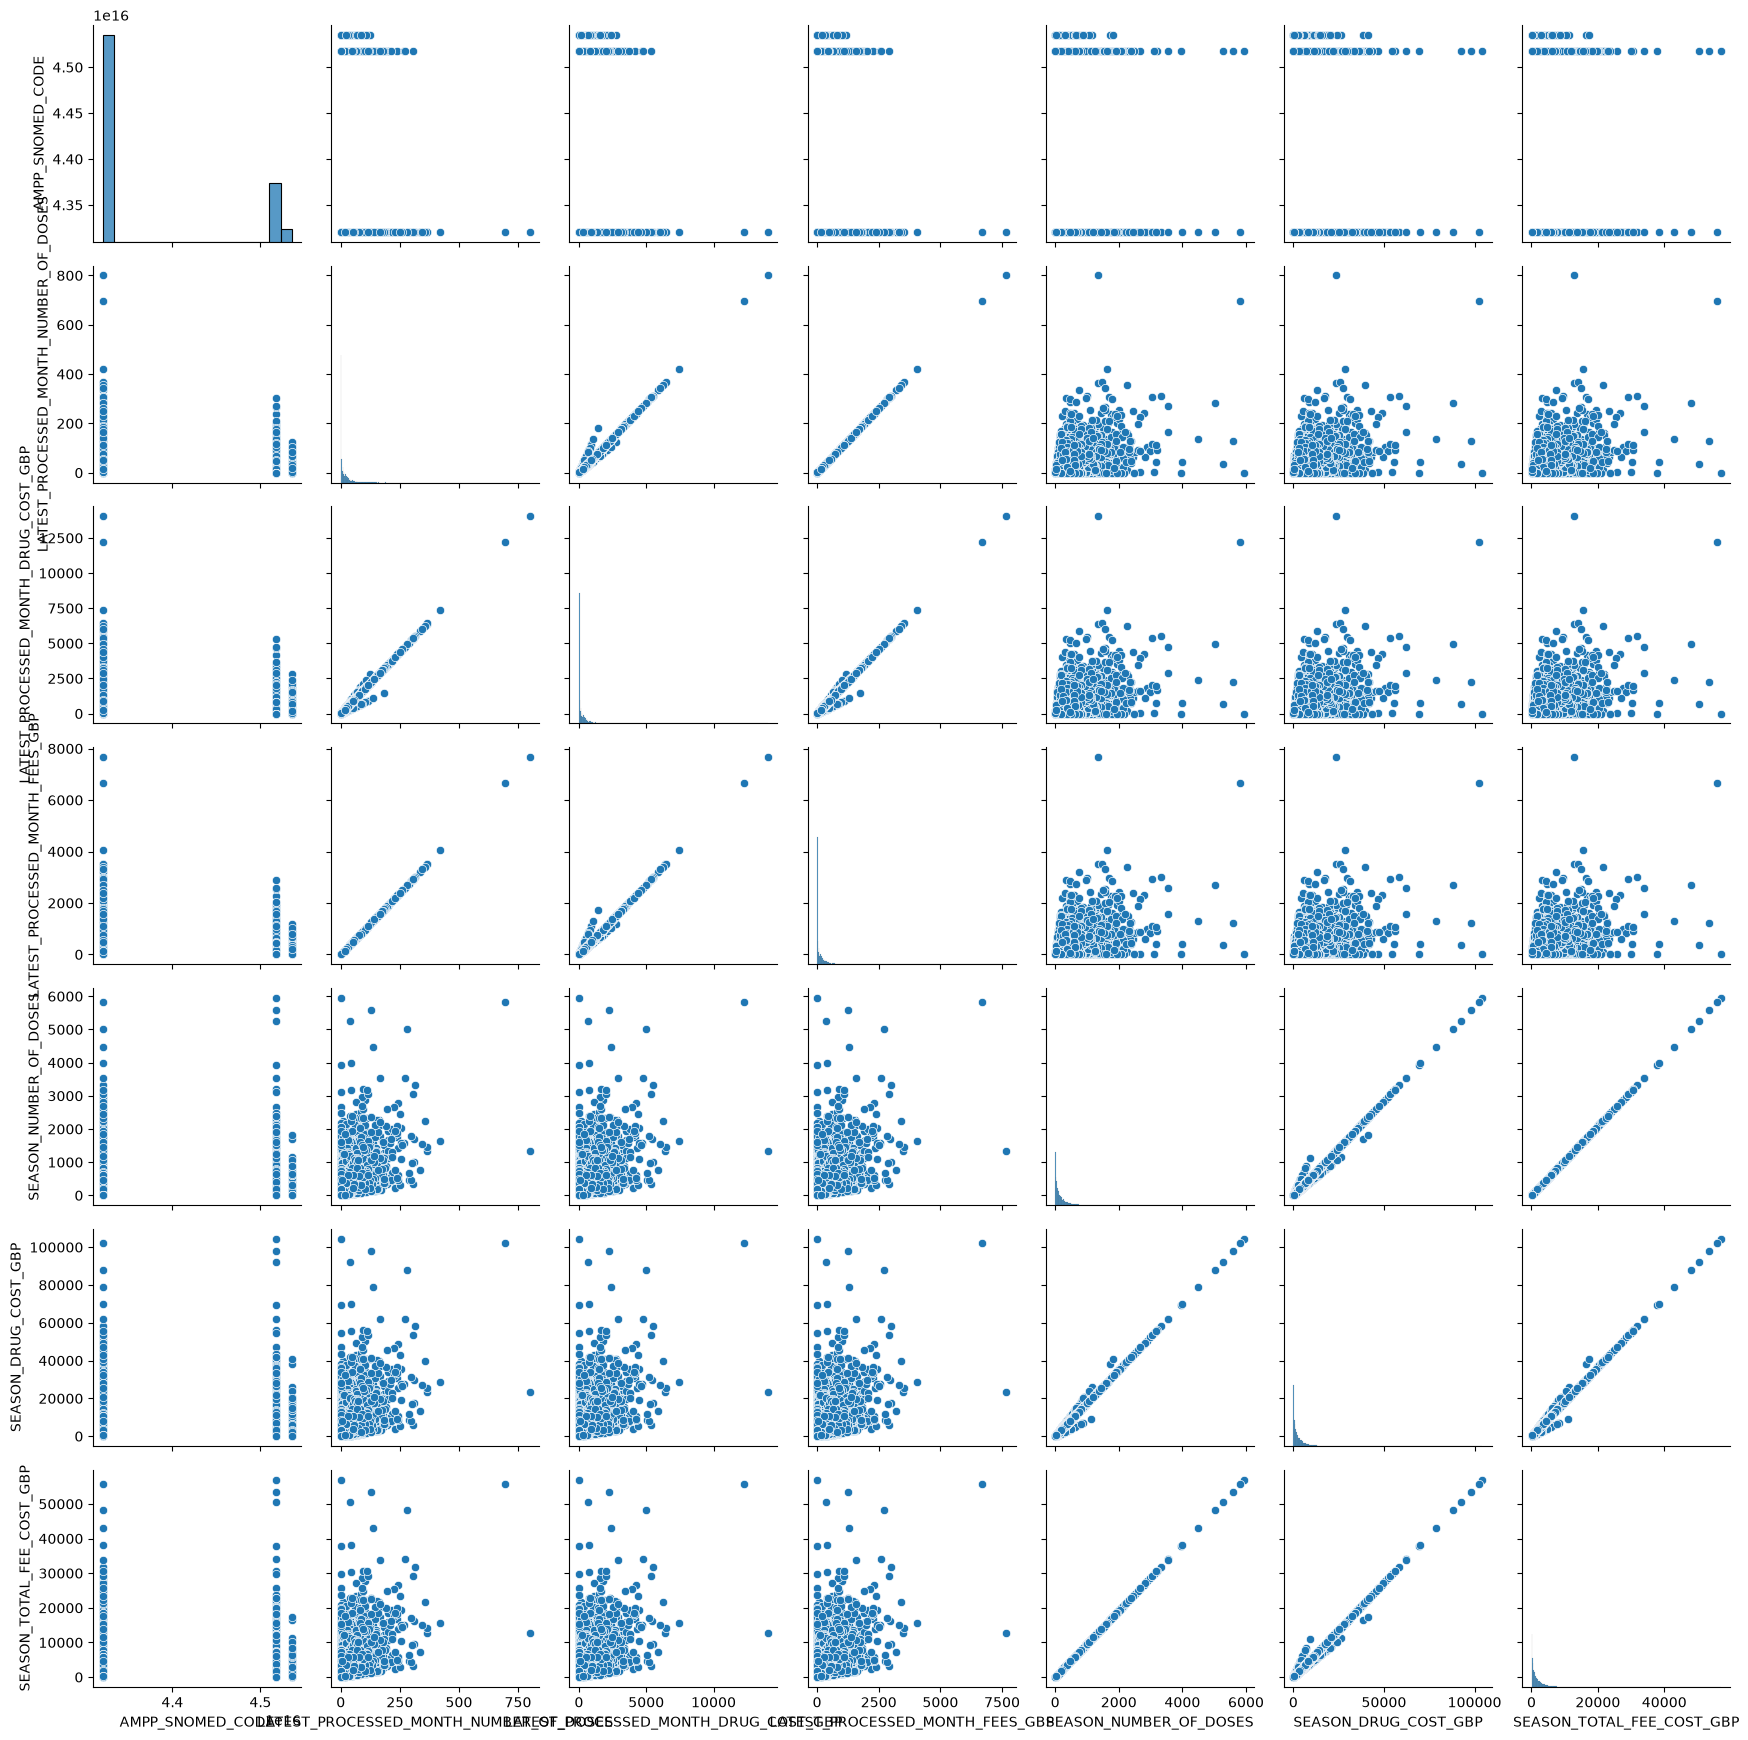

In [61]:
# First look at fields, selection of data and aggregate statistics
print(df.info())
print(df.head())
print(df.describe())

# What shape is the dataset, are there missing values or duplicate rows?
print(f"Data has shape: {df.shape}, {df.duplicated().sum()} duplicate rows and {df["DISPENSER_TRADING_NAME"].isna().sum()} missing values")

# Do any relationships jump out when plotting all the numerical fields?
g = sns.pairplot(df)
plt.tight_layout()
plt.show()

- Dataset has 19 Columns and 25276 rows
- Fields are 13 Str and 6 numberical
- AMPP_SNOMED_CODE field is a code and not an numerical value, so would make more sense as Str
- FLU_SEASON_START_MONTH and LATEST_PROCESSED_MONTH are dates in str dtype
- DISPENSER_TRADING_NAME contains missing values
- Pairplot
    - SEASON_NUMBER_OF_DOSES gives 3 linear relations with SEASON_DRUG_COST_GBP
    - SEASON_TOTAL_FEE_COST_GBP is completely 1:1 linear with SEASON_NUMBER_OF_DOSES


In [62]:
# Exploring what each row corresponds to
# How many unique vaccines do each pharmacy dispense?
vaccines_per_dispenser = (df.groupby("DISPENSER_CODE")["LATEST_PROCESSED_MONTH_DRUG_COST_GBP"].agg("count").sort_values())
print(vaccines_per_dispenser)

# What do the 8 rows for pharmacy FK018 correspond to?
print(df[df["DISPENSER_CODE"] == "FK018"])

# How do the BNF codes relate to the named vaccines?
print(df.groupby(["BNF_PRESENTATION_CODE", "VACCINE_NAME"])["VACCINE_NAME"].agg("count"))

DISPENSER_CODE
FAW19    1
FT629    1
FAX91    1
FC041    1
FC033    1
        ..
FXR17    7
FA366    8
FMA26    8
FK018    8
FDV90    8
Name: LATEST_PROCESSED_MONTH_DRUG_COST_GBP, Length: 9271, dtype: int64
    FLU_SEASON_START_MONTH LATEST_PROCESSED_MONTH REGION_CODE REGION_NAME ICB_CODE                                     ICB_NAME DISPENSER_CODE      DISPENSER_NAME DISPENSER_TRADING_NAME               MANUFACTURER                                       VACCINE_NAME   AMPP_SNOMED_CODE BNF_PRESENTATION_CODE  LATEST_PROCESSED_MONTH_NUMBER_OF_DOSES  LATEST_PROCESSED_MONTH_DRUG_COST_GBP  LATEST_PROCESSED_MONTH_FEES_GBP  SEASON_NUMBER_OF_DOSES  SEASON_DRUG_COST_GBP  SEASON_TOTAL_FEE_COST_GBP
370                2025-09                2025-12         Y56      LONDON      QKK  NHS SOUTH EAST LONDON INTEGRATED CARE BOARD          FK018  CLARITY STORES LTD   BIGGIN HILL PHARMACY                     Sanofi  Efluelda Trivalent influenza vaccine (split vi...  45353611000001108       1404000H0CHAAAL

- Each unique DISPENSER_CODE has 1-8 rows associated with it
- Filtering to FK018 as an example shows the 8 rows correspond to different vaccines
- DISPENSER_NAME has up to 3500+ rows associated (Boots has the most, presumably as a nationwide chain it covers many pharmacies)
- A BNF Presentation Code is a 15-digit code used by the NHS to identify a specific drug, form, and strength
    - There are 7 BNF codes linked to the 10 vaccines (7 unique drugs but some come in single or packs of 10), so the BNF codes may be more useful
- Each row in the dataset therefore represents a Dispensers usage of one of the 10 vaccines
- SEASON_DRUG_COST is total spent on a drug at that dispensery since September 2025, whereas LATEST_PROCESSED_MONTH_DRUG_COST is only for December 2025

## Cleanup

In [63]:
# Cleaning up datatypes, casting into appropriate types
df["AMPP_SNOMED_CODE"] = df["AMPP_SNOMED_CODE"].astype("str")
df["FLU_SEASON_START_MONTH"] = pd.to_datetime(df["FLU_SEASON_START_MONTH"])
df["LATEST_PROCESSED_MONTH"] = pd.to_datetime(df["LATEST_PROCESSED_MONTH"])

# Filling missing values
df["DISPENSER_TRADING_NAME"] = df["DISPENSER_TRADING_NAME"].fillna("Unknown")

print(df.info())


<class 'pandas.DataFrame'>
RangeIndex: 25276 entries, 0 to 25275
Data columns (total 19 columns):
 #   Column                                  Non-Null Count  Dtype         
---  ------                                  --------------  -----         
 0   FLU_SEASON_START_MONTH                  25276 non-null  datetime64[us]
 1   LATEST_PROCESSED_MONTH                  25276 non-null  datetime64[us]
 2   REGION_CODE                             25276 non-null  str           
 3   REGION_NAME                             25276 non-null  str           
 4   ICB_CODE                                25276 non-null  str           
 5   ICB_NAME                                25276 non-null  str           
 6   DISPENSER_CODE                          25276 non-null  str           
 7   DISPENSER_NAME                          25276 non-null  str           
 8   DISPENSER_TRADING_NAME                  25276 non-null  str           
 9   MANUFACTURER                            25276 non-null  str  

- AMPP_SNOMED_CODE cast to string as it is a code and not a numerical value
- Dates cast to datetime to allow plotting
- Missing values in DISPENSER_TRADING_NAME filled with "Unknown"


## Calculation and Visualisation

In [64]:
# Total season spend per drug
season_total_spend_per_drug = df.groupby("BNF_PRESENTATION_CODE")["SEASON_DRUG_COST_GBP"].agg("sum")
print(season_total_spend_per_drug, "\n")

# Combined spending on all drugs
print(f"Total season spending was {season_total_spend_per_drug.sum()} \n")

# Calculation of % of market covered by top 3 drugs
print(f"Three drugs have {round(100 * season_total_spend_per_drug.nlargest(3).sum() / season_total_spend_per_drug.sum(), 1)}% of the market \n")

# Total season spend per manufacturer
season_total_spend_per_manufacturer = df.groupby("MANUFACTURER")["SEASON_DRUG_COST_GBP"].agg("sum")
print(season_total_spend_per_manufacturer,  "\n")

# Calculation of market share for top manufacturer
print(f"Sequirus has {round(100 * season_total_spend_per_manufacturer.loc["Seqirus UK Ltd"] / season_total_spend_per_drug.sum(), 1)}% of the market \n")


BNF_PRESENTATION_CODE
1404000H0AAAMAM    41010102.90
1404000H0AAARAR    25785495.45
1404000H0BYACAR      176296.00
1404000H0CEABAT    11339107.65
1404000H0CFAAAS        4716.00
1404000H0CGAAAU      778616.00
1404000H0CHAAAL     1273950.00
Name: SEASON_DRUG_COST_GBP, dtype: float64 

Total season spending was 80368284.0 

Three drugs have 97.2% of the market 

MANUFACTURER
AstraZeneca UK Ltd               4716.00
Sanofi                       13391673.65
Seqirus UK Ltd               66795598.35
Viatris UK Healthcare Ltd      176296.00
Name: SEASON_DRUG_COST_GBP, dtype: float64 

Sequirus has 83.1% of the market 



- There are 7 different drugs sold as 10 different vaccines. Three drugs have 97% of the market. 
- They are manufactured by 4 different manufacturers but Sequirus has 83.1% of the market. 

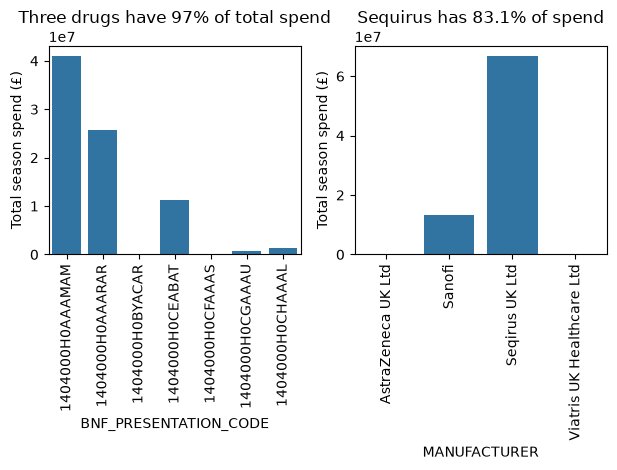

In [65]:
# Plot of Drug against Total season spend, Plot of Manufacturer against Total season spend

fig, ax = plt.subplots(1,2)
sns.barplot(season_total_spend_per_drug, ax=ax[0])
sns.barplot(season_total_spend_per_manufacturer, ax=ax[1])
ax[0].tick_params(axis = 'x', rotation=90)
ax[0].set_title("Three drugs have 97% of total spend")
ax[0].set_ylabel("Total season spend (£)")
ax[1].tick_params(axis = 'x', rotation=90)
ax[1].set_title("Sequirus has 83.1% of spend")
ax[1].set_ylabel("Total season spend (£)")
plt.tight_layout()
plt.show()


- Spending is dominated by 3 vaccines and 2 manufacturers
- Total spending was £80 million with £67 million going to Seqirus and £41 million spent on their Adjuvanted trivalent influenza vaccine and £26 million on their Cell-based trivalent influenza vaccine

In [66]:
# Total doses per drug
season_total_doses_per_drug = df.groupby("BNF_PRESENTATION_CODE")["SEASON_NUMBER_OF_DOSES"].agg("sum")
print(season_total_doses_per_drug, "\n")
print(f"Total doses for season: {season_total_doses_per_drug.sum():.0f} doses \n")

# Average cost per drug dose
average_cost_per_dose = season_total_spend_per_drug / season_total_doses_per_drug
print(average_cost_per_dose)

BNF_PRESENTATION_CODE
1404000H0AAAMAM    2336758
1404000H0AAARAR    1469259
1404000H0BYACAR      22037
1404000H0CEABAT     646103
1404000H0CFAAAS        262
1404000H0CGAAAU      97327
1404000H0CHAAAL      56620
Name: SEASON_NUMBER_OF_DOSES, dtype: int64 

Total doses for season: 4628366 doses 

BNF_PRESENTATION_CODE
1404000H0AAAMAM    17.55
1404000H0AAARAR    17.55
1404000H0BYACAR     8.00
1404000H0CEABAT    17.55
1404000H0CFAAAS    18.00
1404000H0CGAAAU     8.00
1404000H0CHAAAL    22.50
dtype: float64


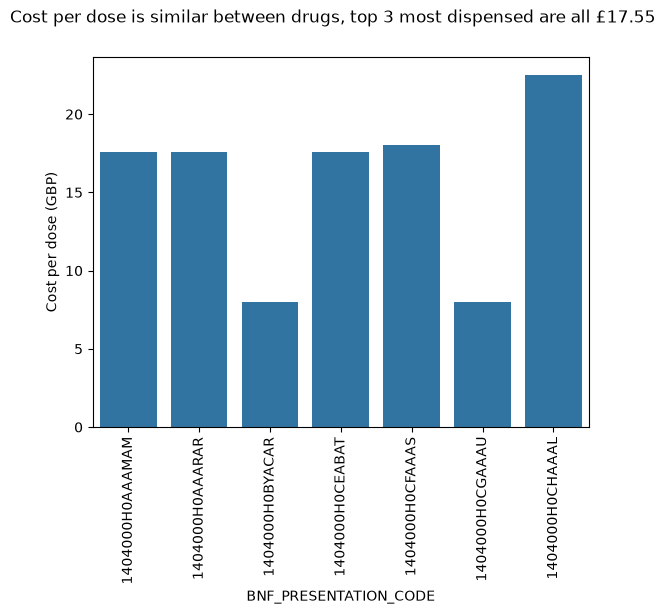

In [67]:
# Plot of Cost per dose against Drug

fig, ax = plt.subplots()

sns.barplot(average_cost_per_dose, ax=ax)
ax.set_ylabel("Cost per dose (GBP)")
ax.tick_params(axis='x', rotation=90)
fig.suptitle("Cost per dose is similar between drugs, top 3 most dispensed are all £17.55")
plt.show()

- Cost per dose varies between £8 and £22.50. The most dispensed drugs are all £17.55, presumably due to a common pricing point negotiated between the NHS and the major suppliers.

In [68]:
# How many different pharmacies are in the dataset?
print(f"There are {vaccines_per_dispenser.shape[0]} different pharmacies contained in the dataset")

There are 9271 different pharmacies contained in the dataset


## Summary
An exploratory data analysis was conducted on a dataset for Flu vaccinations given by community pharmacies in the season September up to December 2025. The data covered 4,628,366 doses administered by 9271 different pharmacies that dispensed 10 different vaccine products covering 7 different drugs (several coming in two sizes of pack). The doses and spend is dominated by 3 drugs which are manufactured by two suppliers. Total spending was £80 million with £67 million going to Seqirus of which £41 million was spent on their Adjuvanted trivalent influenza vaccine and £26 million on their Cell-based trivalent influenza vaccine. The Cost per dose varies between £8 and £22.50, though all three of the top dispensed drugs had an averaged cost of £17.55 per dose.

Futher analysis ideas:
- Why is more than one vaccine product needed?
- Which pharmacies are dispensing uncommon drugs, small or large? (based on total number of vaccines dispensed)
- Does the distribution of drugs dispensed vary throughout the season?
- Does the rate of distribution vary throughout the season?
